# NYC Rodent Inspection - Full Analysis Notebook

**Data source:** NYC Department of Health & Mental Hygiene · Rodent Inspections via NYC Open Data (2009–2025)  
**Coverage:** All analysis powering the interactive web dashboard  

---

### What this notebook covers

| Section | Analysis |
|---|---|
| 1 | Data ingestion & cleaning |
| 2 | Data quality report |
| 3 | KPI summary |
| 4 | Historical trend & ML projection (2026–2028) |
| 5 | Borough comparison |
| 6 | Seasonal patterns |
| 7 | Calendar heatmap (year × month) |
| 8 | Top neighborhoods leaderboard |
| 9 | Inspection type breakdown |
| 10 | Inspection result distribution |
| 11 | Geographic heatmap |
| 12 | Predictive intelligence signals |

> **Standalone** - this notebook reads directly from the raw CSV and imports no project modules.

## Setup

In [3]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

warnings.filterwarnings('ignore')

# ── Plot style ────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor':  'white',
    'axes.facecolor':    '#F8FAFC',
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.grid':         True,
    'grid.color':        '#E2EAF4',
    'grid.linewidth':    0.7,
    'font.family':       'DejaVu Sans',
    'axes.titlesize':    13,
    'axes.labelsize':    11,
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
})

# ── Constants ─────────────────────────────────────────────────────────────────
RAW_CSV = Path('../data/raw/Rodent_Inspection_20260502.csv')

BOROUGH_COLORS = {
    'Manhattan':    '#2563EB',
    'Brooklyn':     '#D97706',
    'Bronx':        '#DC2626',
    'Queens':       '#7C3AED',
    'Staten Island':'#059669',
}
BOROUGHS = list(BOROUGH_COLORS.keys())

RAT_POSITIVE_RESULTS = {'Rat Activity', 'Bait applied'}
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

print('Libraries loaded.')

Libraries loaded.


---
## Section 1 - Data Ingestion & Cleaning

In [4]:
# ── 1a. Load raw CSV ──────────────────────────────────────────────────────────
print(f'Loading {RAW_CSV} ...')
df_raw = pd.read_csv(RAW_CSV, low_memory=False)
print(f'Raw rows: {len(df_raw):,}  |  Columns: {df_raw.shape[1]}')
df_raw.head(3)

Loading ../data/raw/Rodent_Inspection_20260502.csv ...
Raw rows: 2,032,123  |  Columns: 25


,INSPECTION_TYPE,JOB_TICKET_OR_WORK_ORDER_ID,JOB_ID,JOB_PROGRESS,BBL,BORO_CODE,BLOCK,LOT,HOUSE_NUMBER,STREET_NAME,...,BOROUGH,INSPECTION_DATE,RESULT,APPROVED_DATE,LOCATION,COMMUNITY BOARD,COUNCIL DISTRICT,CENSUS TRACT,BIN,NTA
0,Initial,11670593.0,PC6530234,1.0,2.032890e+09,2.0,3289.0,25.0,326,EAST 198 STREET,...,Bronx,08/30/2010 03:23:11 PM,Passed,09/03/2010 10:43:36 AM,"(40.867726534028, -73.887461100839)",7.0,15.0,40502.0,2016678.0,Bedford Park
1,Initial,11758853.0,PC6101553,1.0,1.013290e+09,1.0,1329.0,121.0,245,EAST 55 STREET,...,Manhattan,08/18/2011 12:05:54 PM,Passed,08/19/2011 12:02:56 PM,"(40.758511490599, -73.967433834067)",6.0,4.0,10801.0,1038588.0,East Midtown-Turtle Bay
2,Initial,12504178.0,PC7270050,1.0,NaN,3.0,3141.0,20.0,NaN,MONTIETH STREET,...,Brooklyn,10/10/2018 12:57:02 PM,Passed,10/11/2018 08:59:21 AM,"(40.7014506131434, -73.9354065814951)",NaN,NaN,NaN,NaN,NaN


In [5]:
# ── 1b. Filter corrupted rows ─────────────────────────────────────────────────
# A handful of rows contain stray JSON error payloads in the INSPECTION_TYPE column.
valid_types = {'Initial', 'Treatments', 'Compliance', 'Stoppage', 'Clean Ups'}
df = df_raw[df_raw['INSPECTION_TYPE'].isin(valid_types)].copy()
print(f'After filtering bad rows: {len(df):,}  (removed {len(df_raw) - len(df)} rows)')

After filtering bad rows: 2,032,118  (removed 5 rows)


In [6]:
# ── 1c. Parse dates ───────────────────────────────────────────────────────────
df['inspection_ts'] = pd.to_datetime(
    df['INSPECTION_DATE'], format='%m/%d/%Y %I:%M:%S %p', errors='coerce'
)
null_frac = df['inspection_ts'].isna().mean()
if null_frac > 0.5:
    # Fallback for date-only format
    df['inspection_ts'] = pd.to_datetime(df['INSPECTION_DATE'], format='%m/%d/%Y', errors='coerce')

before = len(df)
df = df.dropna(subset=['inspection_ts'])
print(f'Dropped {before - len(df):,} rows with unparseable dates.')

Dropped 11 rows with unparseable dates.


In [7]:
# ── 1d. Deduplicate, extract time dims, filter years ─────────────────────────
df = df.drop_duplicates(subset=['JOB_TICKET_OR_WORK_ORDER_ID', 'inspection_ts'])

df['year']  = df['inspection_ts'].dt.year.astype(int)
df['month'] = df['inspection_ts'].dt.month.astype(int)

df = df[(df['year'] >= 2009) & (df['year'] <= 2025)].copy()
df['NTA'] = df['NTA'].fillna('Unknown')

print(f'Clean rows: {len(df):,}')
print(f'Year range: {df["year"].min()} – {df["year"].max()}')
print(f'Boroughs  : {sorted(df["BOROUGH"].dropna().unique().tolist())}')

Clean rows: 1,967,453
Year range: 2009 – 2025
Boroughs  : ['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island']


In [8]:
# ── 1e. Derive flag columns ───────────────────────────────────────────────────
df['rat_positive'] = df['RESULT'].isin(RAT_POSITIVE_RESULTS).astype(int)
df['rat_activity'] = (df['RESULT'] == 'Rat Activity').astype(int)
df['bait_applied'] = (df['RESULT'] == 'Bait applied').astype(int)
df['passed']       = (df['RESULT'] == 'Passed').astype(int)
df['other']        = (~df['RESULT'].isin({*RAT_POSITIVE_RESULTS, 'Passed'})).astype(int)

print('Flag columns added.')
df[['RESULT','rat_positive','rat_activity','bait_applied','passed','other']].drop_duplicates('RESULT')

Flag columns added.


,RESULT,rat_positive,rat_activity,bait_applied,passed,other
0,Passed,0,0,0,1,0
6,Rat Activity,1,1,0,0,0
24584,Bait applied,1,0,1,0,0
28792,Monitoring visit,0,0,0,0,1
29980,Failed for Other Reason,0,0,0,0,1
94543,Failed for Rat Activity and Other Reason,0,0,0,0,1
223471,Stoppage done,0,0,0,0,1
329910,Cleanup done,0,0,0,0,1
1763328,NaN,0,0,0,0,1


---
## Section 2 - Data Quality Report

In [9]:
# ── 2a. Null counts per column ────────────────────────────────────────────────
null_report = pd.DataFrame({
    'null_count': df.isnull().sum(),
    'null_pct':   (df.isnull().mean() * 100).round(2)
}).sort_values('null_pct', ascending=False)
null_report[null_report['null_count'] > 0]

,null_count,null_pct
Y_COORD,638415,32.45
X_COORD,638415,32.45
BIN,65150,3.31
BBL,65150,3.31
CENSUS TRACT,52795,2.68
COMMUNITY BOARD,52795,2.68
COUNCIL DISTRICT,52795,2.68
HOUSE_NUMBER,35398,1.80
JOB_ID,17220,0.88
LOCATION,17133,0.87


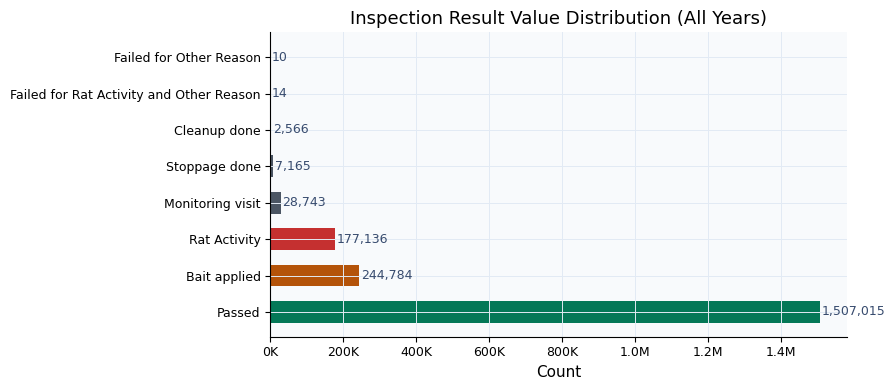

RESULT
Passed                                      1507015
Bait applied                                 244784
Rat Activity                                 177136
Monitoring visit                              28743
Stoppage done                                  7165
Cleanup done                                   2566
Failed for Rat Activity and Other Reason         14
Failed for Other Reason                          10
Name: count, dtype: int64


In [10]:
# ── 2b. RESULT value distribution ────────────────────────────────────────────
result_counts = df['RESULT'].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#047857' if r == 'Passed'
          else '#B45309' if r == 'Bait applied'
          else '#C53030' if r == 'Rat Activity'
          else '#4B5563' for r in result_counts.index]
bars = ax.barh(result_counts.index, result_counts.values, color=colors, height=0.6)
for bar, val in zip(bars, result_counts.values):
    ax.text(val + 5000, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9, color='#374B6E')
ax.set_xlabel('Count')
ax.set_title('Inspection Result Value Distribution (All Years)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M' if x >= 1e6 else f'{x/1e3:.0f}K'))
plt.tight_layout()
plt.show()
print(result_counts)

In [11]:
# ── 2c. Inspection type distribution ─────────────────────────────────────────
print('INSPECTION_TYPE counts:')
print(df['INSPECTION_TYPE'].value_counts())
print()
print('BOROUGH counts:')
print(df['BOROUGH'].value_counts())

INSPECTION_TYPE counts:
INSPECTION_TYPE
Initial       1441400
Treatments     273527
Compliance     242795
Stoppage         7165
Clean Ups        2566
Name: count, dtype: int64

BOROUGH counts:
BOROUGH
Manhattan        684325
Brooklyn         595615
Bronx            514004
Queens           139434
Staten Island     33860
Name: count, dtype: int64


---
## Section 3 - KPI Summary

  Total Inspections   :    1,967,453
  Rat Positive Total  :      421,920  (21.4%)
  ├─ Rat Activity     :      177,136
  └─ Bait Applied     :      244,784
  Passed              :    1,507,015  (76.6%)
  Other outcomes      :       38,518  (2.0%)


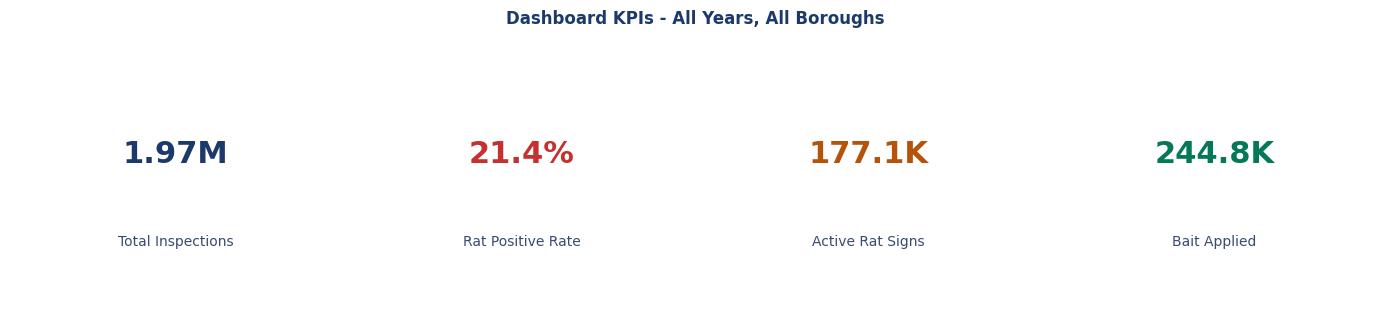

In [12]:
total        = len(df)
rat_pos      = int(df['rat_positive'].sum())
rat_act      = int(df['rat_activity'].sum())
bait         = int(df['bait_applied'].sum())
passed_count = int(df['passed'].sum())
rat_rate     = rat_pos / total * 100

print('=' * 50)
print(f'  Total Inspections   : {total:>12,}')
print(f'  Rat Positive Total  : {rat_pos:>12,}  ({rat_rate:.1f}%)')
print(f'  ├─ Rat Activity     : {rat_act:>12,}')
print(f'  └─ Bait Applied     : {bait:>12,}')
print(f'  Passed              : {passed_count:>12,}  ({passed_count/total*100:.1f}%)')
print(f'  Other outcomes      : {total-rat_pos-passed_count:>12,}  ({(total-rat_pos-passed_count)/total*100:.1f}%)')
print('=' * 50)

# KPI bar chart
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
kpis = [
    ('Total Inspections', total,        '#1B3A6B'),
    ('Rat Positive Rate', rat_rate,     '#C53030'),
    ('Active Rat Signs',  rat_act,      '#B45309'),
    ('Bait Applied',      bait,         '#047857'),
]
for ax, (label, val, color) in zip(axes, kpis):
    ax.set_facecolor('#F0F5FF')
    ax.axis('off')
    fmt_val = f'{val:.1f}%' if label == 'Rat Positive Rate' else (f'{val/1e6:.2f}M' if val >= 1e6 else f'{val/1e3:.1f}K')
    ax.text(0.5, 0.62, fmt_val,   ha='center', va='center', fontsize=22, fontweight='bold', color=color,   transform=ax.transAxes)
    ax.text(0.5, 0.25, label,     ha='center', va='center', fontsize=10,                    color='#374B6E', transform=ax.transAxes)
    for spine in ax.spines.values(): spine.set_visible(False)
plt.suptitle('Dashboard KPIs - All Years, All Boroughs', y=1.02, fontsize=12, color='#1B3A6B', fontweight='bold')
plt.tight_layout()
plt.show()

---
## Section 4 - Historical Trend & ML Projection (2026–2028)

In [13]:
# ── Yearly rat positive rate ──────────────────────────────────────────────────
yearly = (
    df.groupby('year')
    .agg(total=('rat_positive','count'), rat_positive=('rat_positive','sum'))
    .assign(rat_rate=lambda d: d['rat_positive'] / d['total'] * 100)
    .reset_index()
)
print(yearly[['year','total','rat_positive','rat_rate']].to_string(index=False))

 year  total  rat_positive  rat_rate
 2009   8674           153  1.763892
 2010  94096         12011 12.764623
 2011  97746         13353 13.660917
 2012 117551         13205 11.233422
 2013  86349         11201 12.971777
 2014  87264         11802 13.524477
 2015  87914         11402 12.969493
 2016 114717         16350 14.252465
 2017 161934         23676 14.620771
 2018 167712         22881 13.643031
 2019 166536         22307 13.394701
 2020  54016         14269 26.416247
 2021  76026         30134 39.636440
 2022 180522         59502 32.961080
 2023 181823         64006 35.202367
 2024 176606         60094 34.027156
 2025 107967         35574 32.948957


Regression slope : +0.516% per year
2026 projection  : 35.3%
2027 projection  : 35.9%
2028 projection  : 36.4%


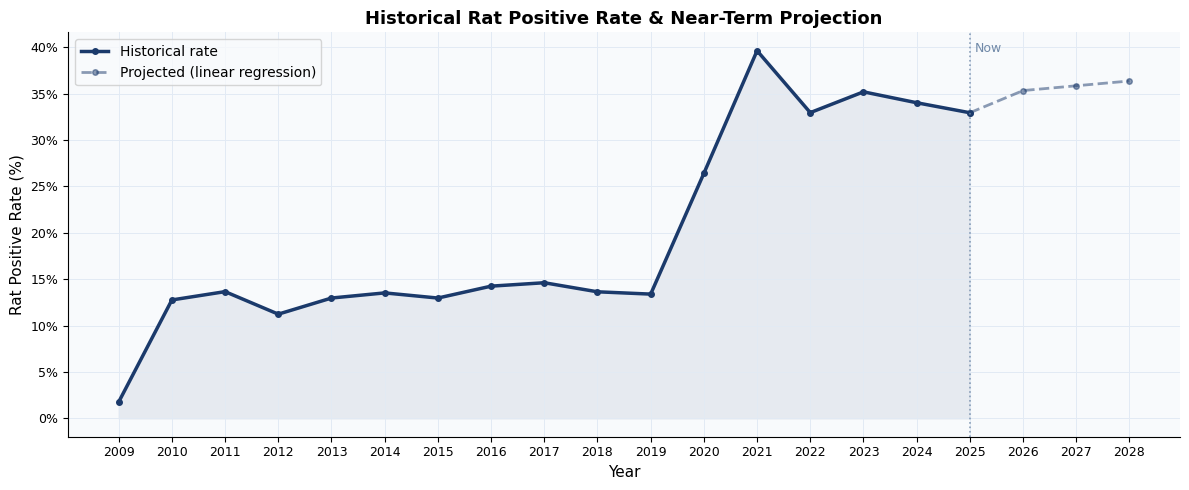

In [14]:
# ── Linear regression on last 6 years → project 2026-2028 ────────────────────
recent = yearly.tail(6)
coeffs = np.polyfit(recent['year'], recent['rat_rate'], 1)
slope, intercept = coeffs
predict = lambda yr: max(0.0, slope * yr + intercept)

proj_years = [2026, 2027, 2028]
proj_rates = [predict(yr) for yr in proj_years]

print(f'Regression slope : {slope:+.3f}% per year')
print(f'2026 projection  : {proj_rates[0]:.1f}%')
print(f'2027 projection  : {proj_rates[1]:.1f}%')
print(f'2028 projection  : {proj_rates[2]:.1f}%')

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.fill_between(yearly['year'], yearly['rat_rate'], alpha=0.08, color='#1B3A6B')
ax.plot(yearly['year'], yearly['rat_rate'], color='#1B3A6B', linewidth=2.5,
        marker='o', markersize=4, label='Historical rate')

# Bridge from last actual to projection
bridge_x = [yearly['year'].iloc[-1]] + proj_years
bridge_y = [yearly['rat_rate'].iloc[-1]] + proj_rates
ax.plot(bridge_x, bridge_y, color='#1B3A6B', linewidth=2, linestyle='--',
        marker='o', markersize=4, alpha=0.5, label='Projected (linear regression)')

# "Now" line at 2025
ax.axvline(2025, color='#7089A8', linewidth=1.2, linestyle=':', alpha=0.8)
ax.text(2025.1, ax.get_ylim()[1] * 0.95, 'Now', color='#7089A8', fontsize=9)

ax.set_xlabel('Year')
ax.set_ylabel('Rat Positive Rate (%)')
ax.set_title('Historical Rat Positive Rate & Near-Term Projection', fontweight='bold')
ax.legend()
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
plt.tight_layout()
plt.show()

---
## Section 5 - Borough Comparison

      BOROUGH  total  rat_positive  rat_activity  bait_applied  passed  rat_rate
     Brooklyn 595615        148730         74692         74038  431765     24.97
       Queens 139434         29902         10699         19203  106943     21.45
        Bronx 514004        103882         36730         67152  403913     20.21
    Manhattan 684325        133930         54484         79446  536785     19.57
Staten Island  33860          5315           530          4785   27608     15.70


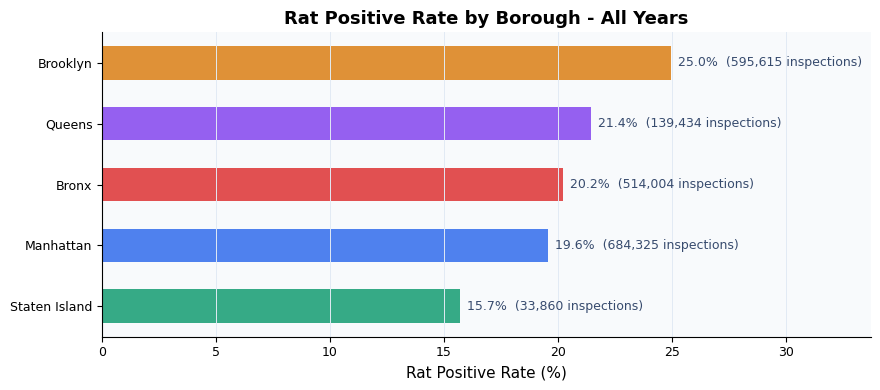

In [15]:
borough_stats = (
    df.groupby('BOROUGH')
    .agg(
        total        =('rat_positive','count'),
        rat_positive =('rat_positive','sum'),
        rat_activity =('rat_activity','sum'),
        bait_applied =('bait_applied','sum'),
        passed       =('passed','sum'),
    )
    .assign(rat_rate=lambda d: (d['rat_positive'] / d['total'] * 100).round(2))
    .sort_values('rat_rate', ascending=False)
    .reset_index()
)
print(borough_stats.to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
colors = [BOROUGH_COLORS.get(b, '#888888') + 'cc' for b in borough_stats['BOROUGH']]
bars = ax.barh(borough_stats['BOROUGH'], borough_stats['rat_rate'], color=colors, height=0.55)
for bar, row in zip(bars, borough_stats.itertuples()):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{row.rat_rate:.1f}%  ({row.total:,} inspections)',
            va='center', fontsize=9, color='#374B6E')
ax.set_xlabel('Rat Positive Rate (%)')
ax.set_title('Rat Positive Rate by Borough - All Years', fontweight='bold')
ax.invert_yaxis()
ax.set_xlim(0, borough_stats['rat_rate'].max() * 1.35)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

---
## Section 6 - Seasonal Patterns

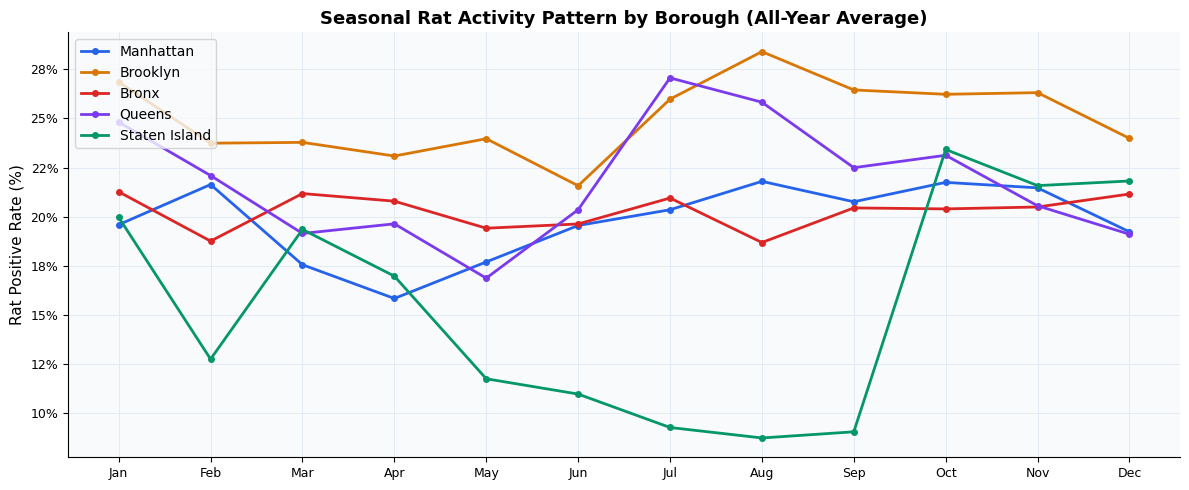

Peak month: Oct (22.9%)


In [16]:
# Monthly rat positive % per borough (all-years average)
monthly_boro = (
    df.groupby(['BOROUGH', 'month'])
    .agg(total=('rat_positive','count'), rat_positive=('rat_positive','sum'))
    .assign(rat_rate=lambda d: d['rat_positive'] / d['total'] * 100)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))
for boro in BOROUGHS:
    sub = monthly_boro[monthly_boro['BOROUGH'] == boro].sort_values('month')
    ax.plot(sub['month'], sub['rat_rate'], marker='o', markersize=4,
            linewidth=2, color=BOROUGH_COLORS[boro], label=boro)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS)
ax.set_ylabel('Rat Positive Rate (%)')
ax.set_title('Seasonal Rat Activity Pattern by Borough (All-Year Average)', fontweight='bold')
ax.legend(loc='upper left')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
plt.tight_layout()
plt.show()

# Peak month overall
monthly_all = (
    df.groupby('month')
    .agg(total=('rat_positive','count'), rat_positive=('rat_positive','sum'))
    .assign(rat_rate=lambda d: d['rat_positive'] / d['total'] * 100)
    .reset_index()
)
peak = monthly_all.loc[monthly_all['rat_rate'].idxmax()]
print(f'Peak month: {MONTHS[int(peak.month)-1]} ({peak.rat_rate:.1f}%)')

---
## Section 7 - Calendar Heatmap (Year × Month)

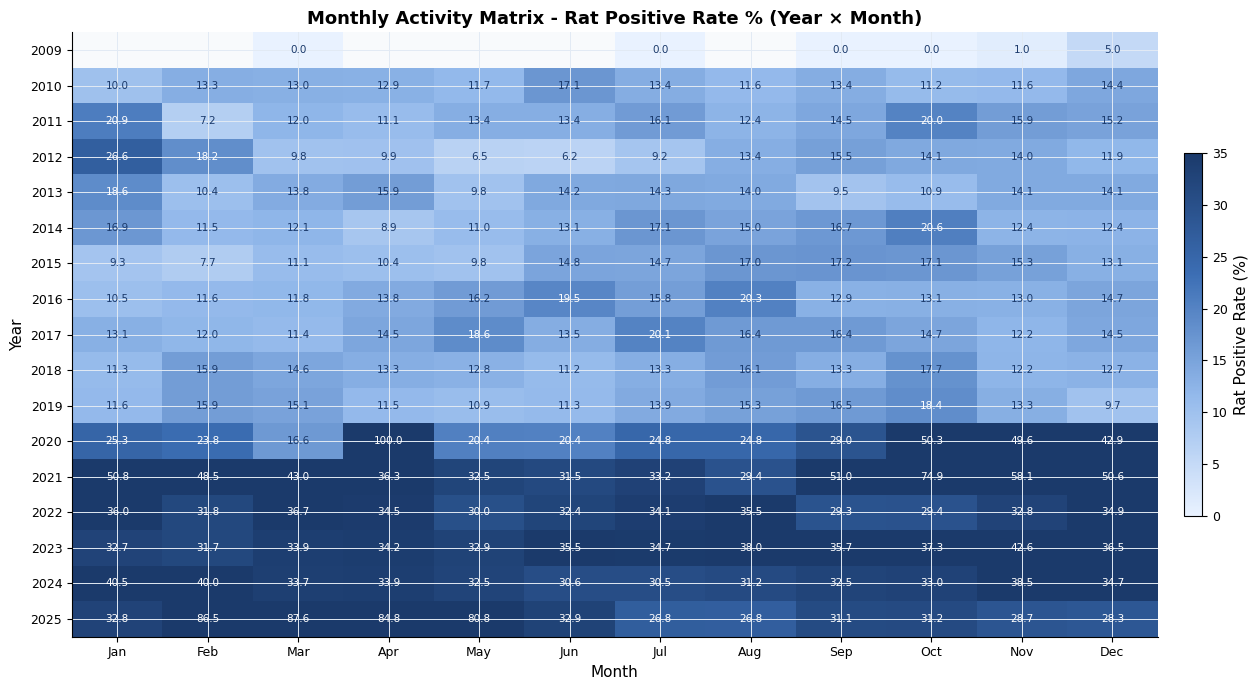

In [17]:
# Year × month rat rate pivot table
cal_data = (
    df.groupby(['year', 'month'])
    .agg(total=('rat_positive','count'), rat_positive=('rat_positive','sum'))
    .assign(rat_rate=lambda d: (d['rat_positive'] / d['total'] * 100).round(2))
    .reset_index()
)
pivot = cal_data.pivot(index='year', columns='month', values='rat_rate')
pivot.columns = MONTHS

fig, ax = plt.subplots(figsize=(14, 7))
cmap = mcolors.LinearSegmentedColormap.from_list(
    'navy_heatmap', ['#E9F2FF', '#93B9EB', '#3C6EB4', '#1B3A6B']
)
im = ax.imshow(pivot.values, aspect='auto', cmap=cmap, vmin=0, vmax=35)

ax.set_xticks(range(12))
ax.set_xticklabels(MONTHS)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index.astype(int))

for yi, yr in enumerate(pivot.index):
    for mi, m in enumerate(MONTHS):
        val = pivot.loc[yr, m]
        if not np.isnan(val):
            text_color = 'white' if val > 18 else '#1B3A6B'
            ax.text(mi, yi, f'{val:.1f}', ha='center', va='center',
                    fontsize=7.5, color=text_color)

plt.colorbar(im, ax=ax, label='Rat Positive Rate (%)', shrink=0.6, pad=0.02)
ax.set_title('Monthly Activity Matrix - Rat Positive Rate % (Year × Month)', fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Year')
plt.tight_layout()
plt.show()

---
## Section 8 - Top Neighborhoods Leaderboard

Top 15 Neighborhoods by Cumulative Rat-Positive Inspections
                            NTA    BOROUGH   total  rat_positive  rat_rate
1     Bedford-Stuyvesant (West)   Brooklyn  114838         28099      24.5
2               Bushwick (West)   Brooklyn   95166         27184      28.6
3     Bedford-Stuyvesant (East)   Brooklyn   81530         17356      21.3
4         Crown Heights (North)   Brooklyn   47806         14927      31.2
5                  East Village  Manhattan   66183         14553      22.0
6   Concourse-Concourse Village      Bronx   38355         11131      29.0
7                Harlem (South)  Manhattan   45022         10128      22.5
8               Bushwick (East)   Brooklyn   38164         10050      26.3
9     Upper West Side (Central)  Manhattan   49609          9455      19.1
10                   Mount Hope      Bronx   32803          9354      28.5
11               Harlem (North)  Manhattan   52072          8776      16.9
12                    Ridgewood     Quee

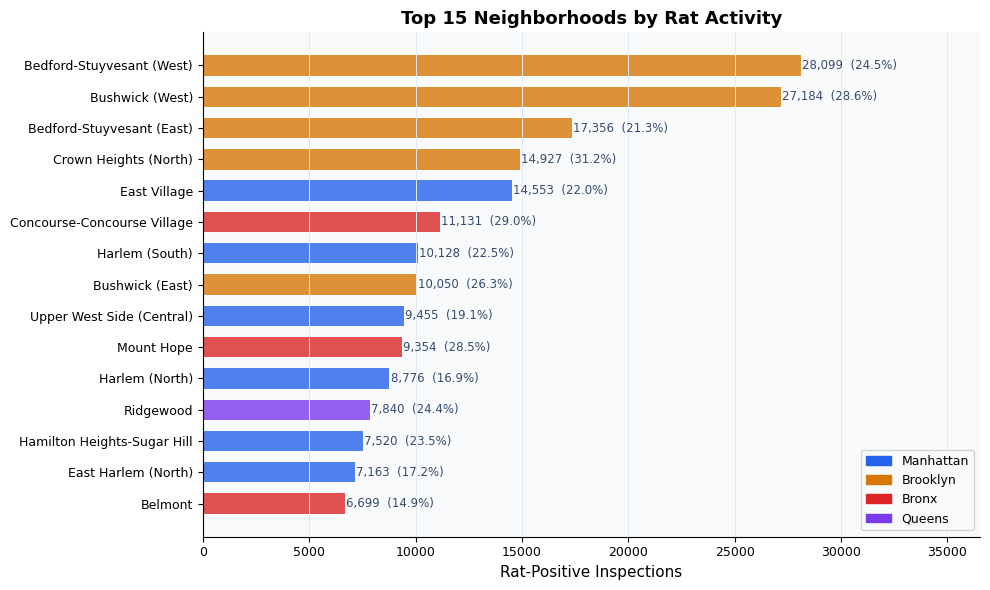

In [18]:
nbhd = (
    df.groupby(['NTA', 'BOROUGH'])
    .agg(
        total        =('rat_positive','count'),
        rat_positive =('rat_positive','sum'),
    )
    .assign(rat_rate=lambda d: (d['rat_positive'] / d['total'] * 100).round(1))
    .reset_index()
    .sort_values('rat_positive', ascending=False)
    .head(15)
    .reset_index(drop=True)
)
nbhd.index += 1
print('Top 15 Neighborhoods by Cumulative Rat-Positive Inspections')
print(nbhd[['NTA','BOROUGH','total','rat_positive','rat_rate']].to_string())

fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = [BOROUGH_COLORS.get(b, '#888888') + 'cc' for b in nbhd['BOROUGH']]
bars = ax.barh(nbhd['NTA'][::-1], nbhd['rat_positive'][::-1], color=bar_colors[::-1], height=0.65)
for bar, row in zip(bars, nbhd.iloc[::-1].itertuples()):
    ax.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2,
            f'{row.rat_positive:,}  ({row.rat_rate}%)',
            va='center', fontsize=8.5, color='#374B6E')
ax.set_xlabel('Rat-Positive Inspections')
ax.set_title('Top 15 Neighborhoods by Rat Activity', fontweight='bold')
ax.set_xlim(0, nbhd['rat_positive'].max() * 1.30)
ax.grid(axis='y', visible=False)

legend_patches = [mpatches.Patch(color=BOROUGH_COLORS[b], label=b) for b in BOROUGHS if b in nbhd['BOROUGH'].values]
ax.legend(handles=legend_patches, loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

---
## Section 9 - Inspection Type Breakdown

INSPECTION_TYPE   total  rat_positive  rat_activity  bait_applied  passed  rat_rate
        Initial 1441400        111305        111305             0 1330060       7.7
     Treatments  273527        244784             0        244784       0      89.5
     Compliance  242795         65831         65831             0  176955      27.1
       Stoppage    7165             0             0             0       0       0.0
      Clean Ups    2566             0             0             0       0       0.0


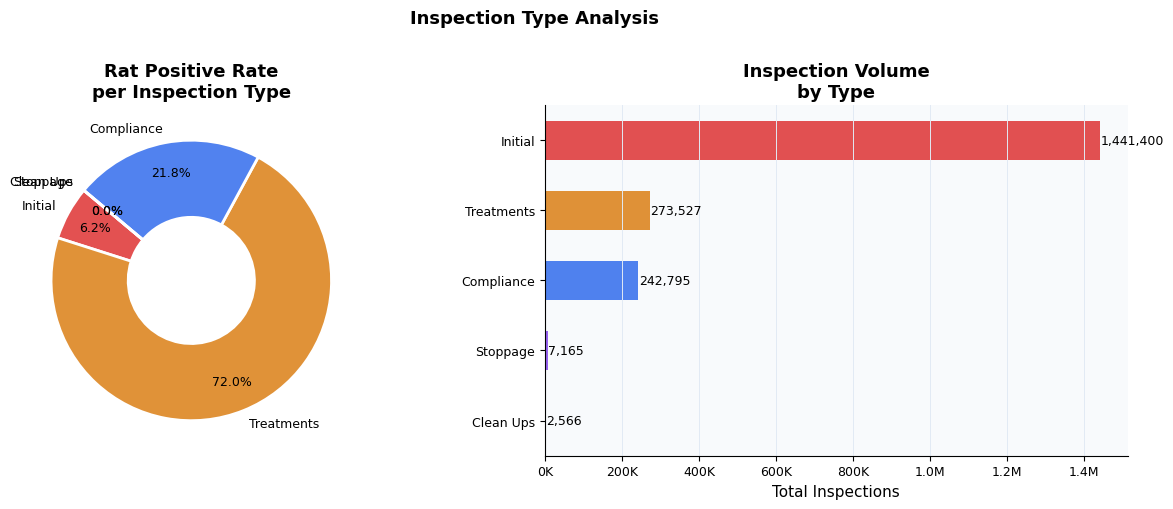

In [19]:
type_stats = (
    df.groupby('INSPECTION_TYPE')
    .agg(
        total        =('rat_positive','count'),
        rat_positive =('rat_positive','sum'),
        rat_activity =('rat_activity','sum'),
        bait_applied =('bait_applied','sum'),
        passed       =('passed','sum'),
    )
    .assign(rat_rate=lambda d: (d['rat_positive'] / d['total'] * 100).round(1))
    .sort_values('total', ascending=False)
    .reset_index()
)
print(type_stats.to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: Rat positive rate per type
type_colors = ['#DC2626cc','#D97706cc','#2563EBcc','#7C3AEDcc','#059669cc']
wedges, texts, autotexts = ax1.pie(
    type_stats['rat_rate'], labels=type_stats['INSPECTION_TYPE'],
    colors=type_colors[:len(type_stats)],
    autopct='%1.1f%%', startangle=140, pctdistance=0.78,
    wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2)
)
for t in autotexts: t.set_fontsize(9)
ax1.set_title('Rat Positive Rate\nper Inspection Type', fontweight='bold')

# Right: Volume per type
bars = ax2.barh(type_stats['INSPECTION_TYPE'][::-1], type_stats['total'][::-1],
                color=type_colors[:len(type_stats)][::-1], height=0.55)
for bar, row in zip(bars, type_stats.iloc[::-1].itertuples()):
    ax2.text(bar.get_width() + 1000, bar.get_y() + bar.get_height()/2,
             f'{row.total:,}', va='center', fontsize=9)
ax2.set_xlabel('Total Inspections')
ax2.set_title('Inspection Volume\nby Type', fontweight='bold')
ax2.grid(axis='y', visible=False)
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}K' if x < 1e6 else f'{x/1e6:.1f}M'))

plt.suptitle('Inspection Type Analysis', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## Section 10 - Inspection Result Distribution

                                  RESULT   count   pct
                                  Passed 1507015 76.60
                            Bait applied  244784 12.44
                            Rat Activity  177136  9.00
                        Monitoring visit   28743  1.46
                           Stoppage done    7165  0.36
                            Cleanup done    2566  0.13
Failed for Rat Activity and Other Reason      14  0.00
                 Failed for Other Reason      10  0.00


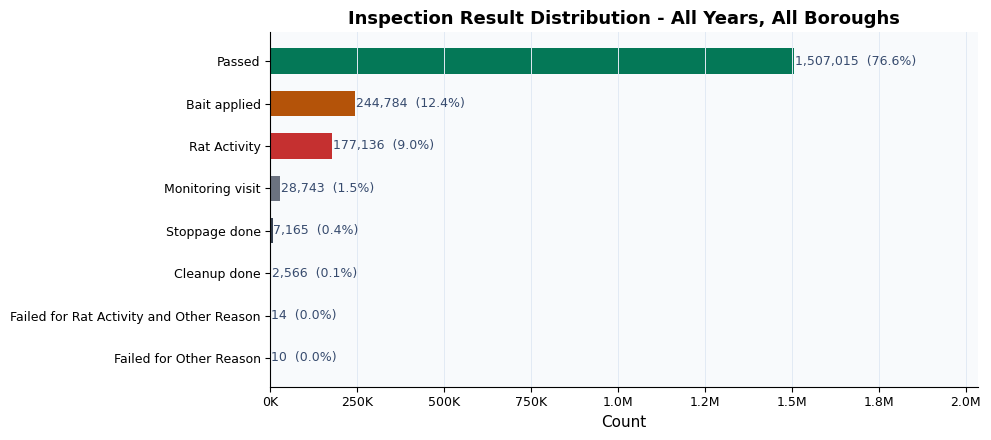

In [20]:
# ── 10a. All-time result breakdown (mirrors notebook 03 countplot) ─────────────
result_counts = df['RESULT'].value_counts().reset_index()
result_counts.columns = ['RESULT', 'count']
result_counts['pct'] = (result_counts['count'] / len(df) * 100).round(2)
print(result_counts.to_string(index=False))

result_palette = {
    'Passed':                                    '#047857',
    'Bait applied':                              '#B45309',
    'Rat Activity':                              '#C53030',
    'Monitoring visit':                          '#6B7280',
    'Stoppage done':                             '#374151',
    'Cleanup done':                              '#4B5563',
    'Failed for Rat Activity and Other Reason':  '#991B1B',
    'Failed for Other Reason':                   '#B91C1C',
}

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [result_palette.get(r, '#888888') for r in result_counts['RESULT']]
bars = ax.barh(result_counts['RESULT'], result_counts['count'], color=colors, height=0.6)
for bar, row in zip(bars, result_counts.itertuples()):
    ax.text(bar.get_width() + 2000, bar.get_y() + bar.get_height()/2,
            f'{row.count:,}  ({row.pct:.1f}%)', va='center', fontsize=9, color='#374B6E')
ax.set_xlabel('Count')
ax.set_title('Inspection Result Distribution - All Years, All Boroughs', fontweight='bold')
ax.invert_yaxis()
ax.set_xlim(0, result_counts['count'].max() * 1.35)
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M' if x >= 1e6 else f'{x/1e3:.0f}K'))
plt.tight_layout()
plt.show()

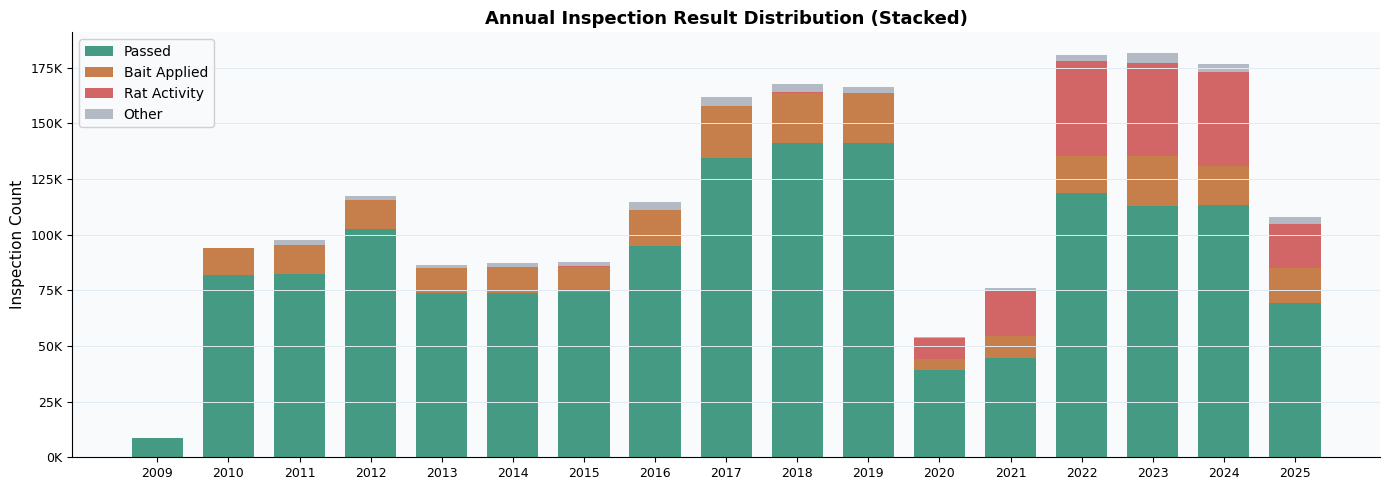


Year-by-year result counts:
 year  passed  bait_applied  rat_activity  other
 2009    8520           153             0      1
 2010   81892         12011             0    193
 2011   82215         13353             0   2178
 2012  102584         13151            54   1762
 2013   73893         11129            72   1255
 2014   73791         11713            89   1671
 2015   74325         11294           108   2187
 2016   94932         16246           104   3435
 2017  134291         23531           145   3967
 2018  141003         22754           127   3828
 2019  141328         22154           153   2901
 2020   39200          5000          9269    547
 2021   44719          9897         20237   1173
 2022  118684         16620         42882   2336
 2023  113051         22361         41645   4766
 2024  113153         17613         42481   3359
 2025   69434         15804         19770   2959


In [21]:
# ── 10b. Stacked bar by year (Passed / Bait Applied / Rat Activity / Other) ───
yearly_result = (
    df.groupby('year')
    .agg(
        passed       =('passed','sum'),
        bait_applied =('bait_applied','sum'),
        rat_activity =('rat_activity','sum'),
        other        =('other','sum'),
    )
    .reset_index()
)

years_list   = yearly_result['year'].tolist()
x            = np.arange(len(years_list))
bar_width    = 0.72

stack_labels  = ['Passed', 'Bait Applied', 'Rat Activity', 'Other']
stack_cols    = ['passed', 'bait_applied', 'rat_activity', 'other']
stack_colors  = ['#047857bb', '#B45309bb', '#C53030bb', '#9CA3AFbb']

fig, ax = plt.subplots(figsize=(14, 5))
bottom = np.zeros(len(years_list))
for col, label, color in zip(stack_cols, stack_labels, stack_colors):
    vals = yearly_result[col].values
    ax.bar(x, vals, width=bar_width, bottom=bottom, label=label, color=color)
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels(years_list, rotation=0)
ax.set_ylabel('Inspection Count')
ax.set_title('Annual Inspection Result Distribution (Stacked)', fontweight='bold')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v/1e3:.0f}K' if v < 1e6 else f'{v/1e6:.1f}M'))
ax.legend(loc='upper left', framealpha=0.9)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print('\nYear-by-year result counts:')
print(yearly_result.to_string(index=False))

---
## Section 11 - Geographic Heatmap

In [22]:
try:
    import folium
    from folium.plugins import HeatMap

    rat_geo = df[df['rat_positive'] == 1].dropna(subset=['LATITUDE', 'LONGITUDE'])
    # Sample to keep the map responsive
    sample = rat_geo.sample(min(50_000, len(rat_geo)), random_state=42)
    points = sample[['LATITUDE', 'LONGITUDE']].values.tolist()

    m = folium.Map(location=[40.71, -73.97], zoom_start=11, tiles='CartoDB positron')
    HeatMap(points, radius=14, blur=12, max_zoom=16).add_to(m)

    # Borough markers
    BOROUGH_CENTERS = {
        'Manhattan':    [40.7831, -73.9712],
        'Brooklyn':     [40.6501, -73.9496],
        'Bronx':        [40.8448, -73.8648],
        'Queens':       [40.7282, -73.7949],
        'Staten Island':[40.5795, -74.1502],
    }
    for boro, coords in BOROUGH_CENTERS.items():
        sub = df[df['BOROUGH'] == boro]
        t = len(sub)
        r = sub['rat_positive'].sum()
        rate = r / t * 100 if t else 0
        folium.CircleMarker(
            location=coords, radius=12 + rate * 0.3,
            color=BOROUGH_COLORS[boro], fill=True, fill_opacity=0.3, weight=2,
            tooltip=f'<b>{boro}</b><br>{rate:.1f}% rat positive<br>{t:,} inspections'
        ).add_to(m)

    display(m)
except ImportError:
    print('folium not installed - run: pip install folium')
    print('Showing static scatter instead.')
    sample = df[df['rat_positive'] == 1].dropna(subset=['LATITUDE','LONGITUDE']).sample(20_000, random_state=42)
    fig, ax = plt.subplots(figsize=(10, 9))
    for boro in BOROUGHS:
        s = sample[sample['BOROUGH'] == boro]
        ax.scatter(s['LONGITUDE'], s['LATITUDE'], s=0.3, alpha=0.4, color=BOROUGH_COLORS[boro], label=boro)
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    ax.set_title('Rat Activity Locations (sample 20K)', fontweight='bold')
    ax.legend(markerscale=10)
    plt.tight_layout(); plt.show()

---
## Section 12 - Predictive Intelligence Signals

╔══════════════════════════════════════════════════════╗
║          PREDICTIVE INTELLIGENCE SIGNALS             ║
╠══════════════════════════════════════════════════════╣
║  5-Year Trend         : Increasing (+0.52%/yr)        ║
║  Peak Season          : Oct        (22.9% avg)         ║
║  Highest Risk Borough : Queens          (36.0% in 2025)  ║
║  2026 Projection      : 35.3%  (linear model)              ║
╚══════════════════════════════════════════════════════╝


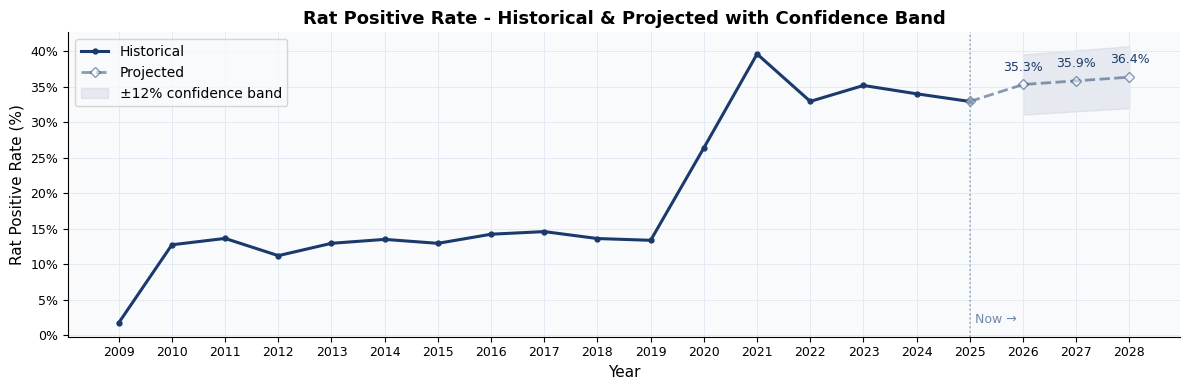

In [23]:
# ── 5-year trend slope ────────────────────────────────────────────────────────
trend_dir = 'Stable'
if abs(slope) >= 0.2:
    trend_dir = f'Increasing (+{slope:.2f}%/yr)' if slope > 0 else f'Decreasing ({slope:.2f}%/yr)'

# ── Peak season ───────────────────────────────────────────────────────────────
peak_month_idx = int(monthly_all.loc[monthly_all['rat_rate'].idxmax(), 'month']) - 1
peak_month_rate = monthly_all['rat_rate'].max()

# ── Highest risk borough (latest year) ────────────────────────────────────────
latest_year = df['year'].max()
latest_borough = (
    df[df['year'] == latest_year]
    .groupby('BOROUGH')
    .agg(total=('rat_positive','count'), rat_positive=('rat_positive','sum'))
    .assign(rat_rate=lambda d: d['rat_positive'] / d['total'] * 100)
    .sort_values('rat_rate', ascending=False)
    .reset_index()
)
high_boro = latest_borough.iloc[0]

# ── 2026 projection ───────────────────────────────────────────────────────────
proj_2026 = predict(2026)

# ── Display ───────────────────────────────────────────────────────────────────
print('╔══════════════════════════════════════════════════════╗')
print('║          PREDICTIVE INTELLIGENCE SIGNALS             ║')
print('╠══════════════════════════════════════════════════════╣')
print(f'║  5-Year Trend         : {trend_dir:<30}║')
print(f'║  Peak Season          : {MONTHS[peak_month_idx]:<10} ({peak_month_rate:.1f}% avg)         ║')
print(f'║  Highest Risk Borough : {high_boro["BOROUGH"]:<15} ({high_boro["rat_rate"]:.1f}% in {latest_year})  ║')
print(f'║  2026 Projection      : {proj_2026:.1f}%  (linear model)              ║')
print('╚══════════════════════════════════════════════════════╝')

# ── Projection chart ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(yearly['year'], yearly['rat_rate'], color='#1B3A6B', linewidth=2.2,
        marker='o', markersize=3.5, label='Historical')

conf_x = np.array(proj_years)
conf_y = np.array(proj_rates)
ax.plot([yearly['year'].iloc[-1]] + proj_years,
        [yearly['rat_rate'].iloc[-1]] + proj_rates,
        color='#1B3A6B', linewidth=2, linestyle='--', alpha=0.5,
        marker='D', markersize=5, markerfacecolor='white', label='Projected')

ax.fill_between(conf_x, conf_y * 0.88, conf_y * 1.12,
                color='#1B3A6B', alpha=0.08, label='±12% confidence band')
ax.axvline(2025, color='#7089A8', linewidth=1.2, linestyle=':', alpha=0.7)
ax.text(2025.1, yearly['rat_rate'].min(), 'Now →', color='#7089A8', fontsize=9)

for yr, rate in zip(proj_years, proj_rates):
    ax.annotate(f'{rate:.1f}%', xy=(yr, rate), xytext=(0, 10),
                textcoords='offset points', ha='center', fontsize=9, color='#1B3A6B')

ax.set_xlabel('Year')
ax.set_ylabel('Rat Positive Rate (%)')
ax.set_title('Rat Positive Rate - Historical & Projected with Confidence Band', fontweight='bold')
ax.legend()
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
plt.tight_layout()
plt.show()

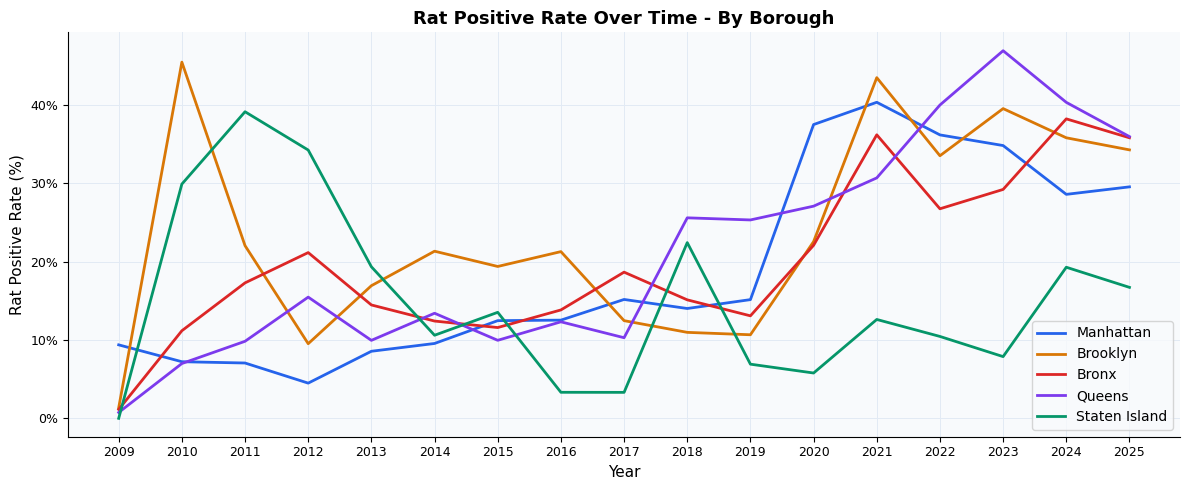

In [24]:
# ── Borough-level trend comparison ───────────────────────────────────────────
boro_yearly = (
    df.groupby(['BOROUGH', 'year'])
    .agg(total=('rat_positive','count'), rat_positive=('rat_positive','sum'))
    .assign(rat_rate=lambda d: d['rat_positive'] / d['total'] * 100)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 5))
for boro in BOROUGHS:
    sub = boro_yearly[boro_yearly['BOROUGH'] == boro].sort_values('year')
    ax.plot(sub['year'], sub['rat_rate'], linewidth=2,
            color=BOROUGH_COLORS[boro], label=boro)

ax.set_xlabel('Year')
ax.set_ylabel('Rat Positive Rate (%)')
ax.set_title('Rat Positive Rate Over Time - By Borough', fontweight='bold')
ax.legend()
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
plt.tight_layout()
plt.show()

---
## Summary

| Analysis | Key Finding |
|---|---|
| Total inspections | See KPI section above |
| Trend | 5-year linear slope (see Section 4) |
| Highest risk borough | See Section 12 |
| Peak month | See Section 6 |
| 2026 projection | Linear model (ML integration planned) |

All charts above power the interactive web dashboard at `web/index.html`.  
ML model integration will replace the linear regression projection in a future iteration.